# Demo 4: Quantile GAMs with qgam (Python / pymgcv)

This notebook is the Python version of [`R_demos/4_qgam.R`](../R_demos/4_qgam.R).
A standard GAM models the **mean** of the response. A **quantile GAM** models a chosen
**quantile** instead (e.g. the 90% quantile, the value that the response falls below 90%
of the time), without assuming a distribution for the response. The R package
[`qgam`](https://cran.r-project.org/package=qgam) fits these models.

The notebook has two parts:

1. **Motorcycle crash data**: quantile GAMs for head acceleration over time, for one
   quantile and for several quantiles at once.
2. **Rainfall in Paraná (Brazil)**: quantile GAMs with spatial, seasonal and
   space-time effects, and checks that the fitted quantiles are right.

## R → Python summary

pymgcv has no quantile GAMs, so the models are fitted with `qgam` through rpy2. The
fitted model is a normal mgcv `gam` object, so we **wrap it in a pymgcv `GAM`** (helper
`fit_qgam` below). After that, pymgcv's `predict`, `summary`, `partial_effect` and
plotting functions all work on it.

| R | Python in this notebook | Notes |
|---|---|---|
| `qgam(form, data, qu)` | `fit_qgam(predictors, data, qu)` helper | ❌ not in pymgcv: qgam through rpy2, wrapped in a pymgcv `GAM` |
| `mqgam(form, data, qu = c(...))` + `qdo(fit, q, ...)` | `fit_mqgam(...)` helper, returns one `GAM` per quantile | ❌ qgam through rpy2 |
| `s(times, bs = "ad")` | `S("times", bs=AdaptiveSmooth())` | ⚠️ pymgcv has no adaptive smooth basis; we define it in 5 lines (as in Demo 3) |
| `predict(fit, se = TRUE)` | `fit.predict(compute_se=True)` | pymgcv ✅ |
| `summary(fit)` | `fit.summary()` | pymgcv ✅ |
| `plot(fit)`, `plot(fitM, select = ...)` | `gplt.plot(fit)`, `gplt.continuous_1d/2d(...)` | pymgcv ✅ |
| `qq(fit, CI = "normal")` | rpy2 + mgcViz | ❌ not in pymgcv |
| `check1D(fit, x) + l_gridQCheck1D()` | `quantile_check_1d()` helper | ⚠️ not in pymgcv, built with numpy/scipy/matplotlib |
| `check2D(fit, x1, x2) + l_gridQCheck2D()` | `quantile_check_2d()` helper | ⚠️ not in pymgcv, built with matplotlib `hexbin` |
| `plotSlice(sm(fit, 1), fix = ...)` | `partial_effect` on a grid + `pcolormesh` | numpy/matplotlib |
| `plotRGL(sm(fit, 1))` | plotly 3D surface | interactive, as in Demo 2 |

> **Requirements:** `qgam` and `mgcViz` are installed by `pixi install`. The datasets come
> from `MASS` (installed) and from the `testGam` GitHub repository (downloaded directly),
> so `pixi run install-r-github` is **not** needed for this notebook.

In [1]:
%matplotlib inline
import tempfile
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import rpy2.robjects as ro
from IPython.display import Image, display
from rpy2.robjects.packages import importr
from scipy.spatial import cKDTree
from scipy.stats import binom

import pymgcv.plot as gplt
from pymgcv.basis_functions import AbstractBasis, CubicSpline, ThinPlateSpline
from pymgcv.families import AbstractFamily, GauLSS, Gaussian
from pymgcv.gam import GAM, FitState
from pymgcv.rpy_utils import data_to_rdf, to_py
from pymgcv.terms import S, T
from pymgcv.utils import load_rdata_dataframe_from_url
from plot_helpers import plot_surface_static  # helper file next to the notebooks

# R packages, used through rpy2
grdevices = importr("grDevices")
qgam = importr("qgam")
importr("mgcViz")
importr("MASS")
# Hide a ggplot2 deprecation warning triggered inside mgcViz
ro.r("options(lifecycle_verbosity = 'quiet')")

## Helper functions

### Fitting quantile GAMs from Python

- `AdaptiveSmooth`: the adaptive smoothing basis `bs = "ad"`, which lets the
  wiggliness of the smooth change along `x`. pymgcv doesn't have it, but any mgcv basis can
  be added by subclassing `AbstractBasis` (same as in Demo 3).
- `fit_qgam(predictors, data, qu)`: writes the model with pymgcv terms, fits it with R's
  `qgam::qgam()` and returns a pymgcv `GAM`. The model is described with the same
  dictionary as a pymgcv `GAM`:
  - one entry, e.g. `{"accel": [S("times")]}`, is the formula `accel ~ s(times)`;
  - two entries, e.g. `{"accel": [S("times")], "scale": [S("times")]}`, is the list
    `list(accel ~ s(times), ~ s(times))`. The second formula is not a second quantile:
    qgam uses it to let the **learning rate** (how sharply the loss is smoothed) change
    with the covariates. The final model still has one linear predictor, for the quantile.
- `fit_mqgam(predictors, data, qus)`: the same for several quantiles with
  `qgam::mqgam()`. It returns a list with one pymgcv `GAM` for each quantile, like
  `qdo(fit, q)` in R.

qgam prints its progress while it estimates the learning rate (one dot per evaluation).

In [2]:
@dataclass
class AdaptiveSmooth(AbstractBasis):
    """mgcv's adaptive smoothing basis, s(x, bs = "ad")."""

    def __str__(self) -> str:
        return "ad"

    def _pass_to_s(self) -> dict:
        return {}


class FittedFamily(AbstractFamily):
    """Wraps the family of a model fitted in R (here qgam's 'elf' family)."""

    def __init__(self, rfamily):
        self.rfamily = rfamily
        self.n_observed_predictors = 1
        self.n_unobserved_predictors = 0


def _formulae(predictors):
    """R formula(e) for the predictors: one formula, or a list of two as in qgam."""
    # GauLSS is only used here to let pymgcv build a list of two formulae
    template = GAM(predictors, family=GauLSS() if len(predictors) == 2 else Gaussian())
    return template._to_r_formulae(), template.referenced_variables


def _wrap(predictors, rgam, data):
    """Wrap a fitted mgcv/qgam object in a pymgcv GAM (quantile predictor only)."""
    response, terms = next(iter(predictors.items()))
    gam = GAM({response: terms}, family=FittedFamily(rgam.rx2("family")))
    gam.fit_state = FitState(rgam=rgam, data=data)
    return gam


def fit_qgam(predictors, data, qu, discrete=False):
    """Python version of qgam::qgam(). Returns a fitted pymgcv GAM."""
    formulae, variables = _formulae(predictors)
    rgam = qgam.qgam(formulae, data=data_to_rdf(data, include=variables), qu=qu,
                     discrete=discrete)
    return _wrap(predictors, rgam, data)


def fit_mqgam(predictors, data, qus, discrete=False):
    """Python version of qgam::mqgam() + qdo(). Returns one pymgcv GAM per quantile."""
    formulae, variables = _formulae(predictors)
    rfit = qgam.mqgam(formulae, data=data_to_rdf(data, include=variables),
                      qu=ro.FloatVector(qus), discrete=discrete)
    return [_wrap(predictors, qgam.qdo(rfit, float(q)), data) for q in qus]

### Checking the fitted quantile

If the model for the quantile `qu` is right, a proportion `qu` of the observations should
be **below** the fitted quantile, i.e. have a negative residual. These helpers check this
locally, like mgcViz's `l_gridQCheck1D` and `l_gridQCheck2D`:

- `quantile_check_1d(x, res, qu)`: splits `x` into 20 bins and plots the proportion of
  negative residuals in each bin (black dots). The red crosses show the 80% interval that
  this proportion would have, given the number of points in the bin, if the model were
  right (binomial distribution). The dashed line is `qu`.
- `quantile_check_2d(x1, x2, res, qu)`: the same on hexagons in 2D. The colour is the
  proportion minus `qu`, divided by its standard error `sqrt(qu (1 - qu) / n)`, so values
  far beyond ±2 (dark red or dark blue) show areas where the fitted quantile is too low or
  too high.

`show_r_plot(r_code)` runs R plotting code and shows the figure in the notebook (as in
Demos 2 and 3). We use it to show the original mgcViz plots next to the Python ones.

In [3]:
def quantile_check_1d(x, res, qu, n=20, level=0.8, ax=None, xlabel="x"):
    """Python version of mgcViz's check1D(fit, x) + l_gridQCheck1D()."""
    x = np.asarray(x, dtype=float)
    res = np.asarray(res, dtype=float)
    grid = np.linspace(x.min(), x.max(), n)
    bins = np.clip(np.searchsorted(grid, x, side="right") - 1, 0, n - 2)
    used = np.unique(bins)

    x_mid = np.array([x[bins == b].mean() for b in used])
    count = np.array([(bins == b).sum() for b in used])
    prop_neg = np.array([(res[bins == b] <= 0).mean() for b in used])
    lower = binom.ppf((1 - level) / 2, count, qu) / count
    upper = binom.isf((1 - level) / 2, count, qu) / count

    ax = plt.gca() if ax is None else ax
    ax.axhline(qu, linestyle="--", color="black", linewidth=1)
    ax.scatter(x_mid, lower, marker="+", color="red", s=40)
    ax.scatter(x_mid, upper, marker="+", color="red", s=40)
    ax.scatter(x_mid, prop_neg, color="black", zorder=3)
    ax.set(xlabel=xlabel, ylabel="Proportion of neg. resid.")
    return ax


def quantile_check_2d(x1, x2, res, qu, gridsize=20, ax=None, xlabel="x1", ylabel="x2"):
    """Python version of mgcViz's check2D(fit, x1, x2) + l_gridQCheck2D()."""
    def standardised(r):
        r = np.asarray(r)
        return ((r <= 0).mean() - qu) / np.sqrt(qu * (1 - qu) / len(r))

    ax = plt.gca() if ax is None else ax
    hb = ax.hexbin(x1, x2, C=res, reduce_C_function=standardised, gridsize=gridsize,
                   cmap="coolwarm")
    lim = np.abs(hb.get_array()).max()
    hb.set_clim(-lim, lim)
    ax.figure.colorbar(hb, ax=ax, label="(prop. neg. resid. - qu) / s.e.")
    ax.set(xlabel=xlabel, ylabel=ylabel)
    return ax


def show_r_plot(r_code, width=7, height=5, res=100):
    """Run R plotting code and display the resulting figure in the notebook."""
    with tempfile.NamedTemporaryFile(suffix=".png", delete=False) as f:
        path = f.name
    grdevices.png(path, width=width, height=height, units="in", res=res)
    try:
        ro.r(r_code)
    finally:
        grdevices.dev_off()
    display(Image(path))

# Part 1: Motorcycle crash data

The `mcycle` dataset (R package `MASS`) comes from simulated motorcycle crashes used to
test crash helmets:

- **`times`**: time after the impact, in milliseconds.
- **`accel`**: head acceleration, in g.

The spread of `accel` changes a lot over time: almost none before 15 ms, very large
between 15 and 40 ms. A model for the mean alone doesn't describe this, but models for
several quantiles do.

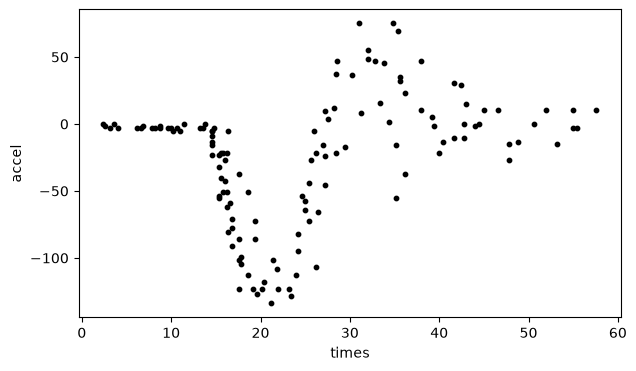

In [4]:
ro.r("data(mcycle)")
mcycle = to_py(ro.r("mcycle")).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(mcycle["times"], mcycle["accel"], s=10, color="black")
ax.set(xlabel="times", ylabel="accel");

## Model for the 90% quantile

R:

```r
fit09 <- qgam(accel ~ s(times, k = 20, bs = "ad"), data = mcycle, qu = 0.9)
```

The adaptive basis (`bs = "ad"`) lets the curve be flat before the impact and wiggly
after it.

In [5]:
fit09 = fit_qgam(
    {"accel": [S("times", k=20, bs=AdaptiveSmooth())]},
    data=mcycle,
    qu=0.9,
)

Estimating learning rate. Each dot corresponds to a loss evaluation. 
qu = 0.9.....................done 


`predict(compute_se=True)` returns the fitted 90% quantile and its standard error. The
red lines are ± 2 standard errors.

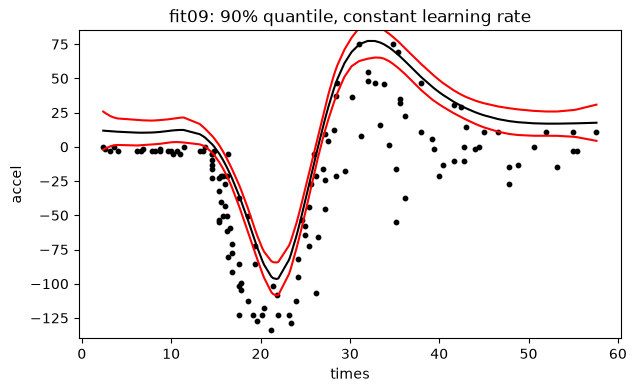

In [6]:
def plot_quantile_fit(fit, title, ylim=(-140, 90)):
    pred = fit.predict(compute_se=True)["accel"]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.scatter(mcycle["times"], mcycle["accel"], s=10, color="black")
    ax.plot(mcycle["times"], pred.fit, color="black")
    ax.plot(mcycle["times"], pred.fit + 2 * pred.se, color="red")
    ax.plot(mcycle["times"], pred.fit - 2 * pred.se, color="red")
    ax.set(xlabel="times", ylabel="accel", ylim=ylim, title=title)


plot_quantile_fit(fit09, "fit09: 90% quantile, constant learning rate", ylim=(-140, 85))

The confidence band is too narrow before 15 ms, where there is little variation, and
looks too wide later on. The reason is that qgam uses **one learning rate** for all
`times`, but the spread of the data changes a lot.

## Learning rate that depends on `times`

R:

```r
fit09_2 <- qgam(list(accel ~ s(times, k = 20, bs = "ad"),
                           ~ s(times)),
                data = mcycle, qu = 0.9)
```

The second formula `~ s(times)` lets the learning rate change with `times`. In Python it
is the second entry of the dictionary (its name, here `"scale"`, can be anything).

Estimating learning rate. Each dot corresponds to a loss evaluation. 
qu = 0.9.................done 


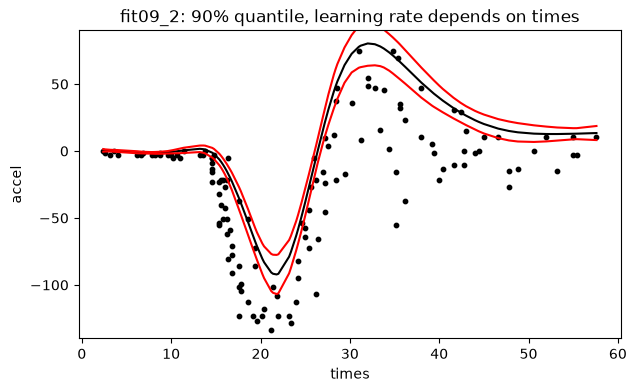

In [7]:
fit09_2 = fit_qgam(
    {
        "accel": [S("times", k=20, bs=AdaptiveSmooth())],  # the 90% quantile
        "scale": [S("times")],  # learning rate, changes with times
    },
    data=mcycle,
    qu=0.9,
)
plot_quantile_fit(fit09_2, "fit09_2: 90% quantile, learning rate depends on times")

The band is now narrow before the impact and wider where the data vary more.

The fitted object is an mgcv `gam` with the extra class `qgam`, and the family is the
*extended log-F* (`elf`) family that qgam uses to fit quantiles:

In [8]:
print(list(fit09_2.fit_state.rgam.rclass))
print(fit09_2.summary())

['qgam', 'gam', 'glm', 'lm']

Family: elf 
Link function: identity 

Formula:
accel ~ s(times, k = 20L, bs = "ad") + 1

Parametric coefficients:
            Estimate Std. Error z value Pr(>|z|)
(Intercept)    2.305      1.508   1.528    0.126

Approximate significance of smooth terms:
           edf Ref.df Chi.sq p-value    
s(times) 11.58  13.16    548  <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

R-sq.(adj) =  0.673   Deviance explained = 97.3%
-REML = 573.57  Scale est. = 1         n = 133


> In R, the demo then calls `getViz(fit09_2, nsim = 100)` and notes that `nsim` doesn't
> make sense here: a quantile GAM doesn't assume a distribution for the response, so
> there is nothing to simulate from. We skip that line.

## Several quantiles at once

R:

```r
fitMQ <- mqgam(list(accel ~ s(times, k = 20, bs = "ad"), ~ s(times)),
               data = mcycle, qu = c(0.1, 0.25, 0.5, 0.75, 0.9))
```

`fit_mqgam` returns a list with one pymgcv `GAM` per quantile, so `fits_mq[0]` is the
model for the 10% quantile (`qdo(fitMQ, 0.1)` in R).

In [9]:
QUS = [0.1, 0.25, 0.5, 0.75, 0.9]
fits_mq = fit_mqgam(
    {
        "accel": [S("times", k=20, bs=AdaptiveSmooth())],
        "scale": [S("times")],
    },
    data=mcycle,
    qus=QUS,
)

Estimating learning rate. Each dot corresponds to a loss evaluation. 
qu = 0.5.........................done 
qu = 0.25............done 
qu = 0.75..........done 
qu = 0.1..................done 
qu = 0.9..............done 


`qdo(fitMQ, 0.1, summary)` and `qdo(fitMQ, 0.1, plot)`:


Family: elf 
Link function: identity 

Formula:
accel ~ s(times, k = 20L, bs = "ad") + 1

Parametric coefficients:
            Estimate Std. Error z value Pr(>|z|)    
(Intercept)  -54.736      2.076  -26.37   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Approximate significance of smooth terms:
           edf Ref.df Chi.sq p-value    
s(times) 8.654  9.429   1184  <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

R-sq.(adj) =  0.645   Deviance explained = 90.2%
-REML = 584.94  Scale est. = 1         n = 133


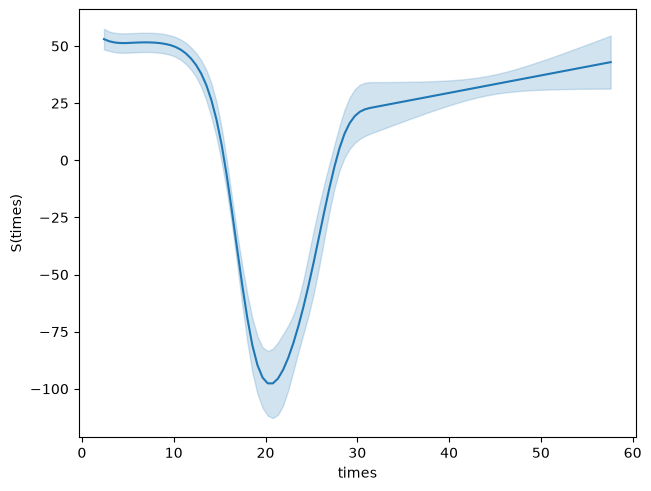

In [10]:
print(fits_mq[0].summary())
gplt.plot(fits_mq[0]);

`plot(fitMQ_viz)` in R draws the effect of `times` for all quantiles in one plot:

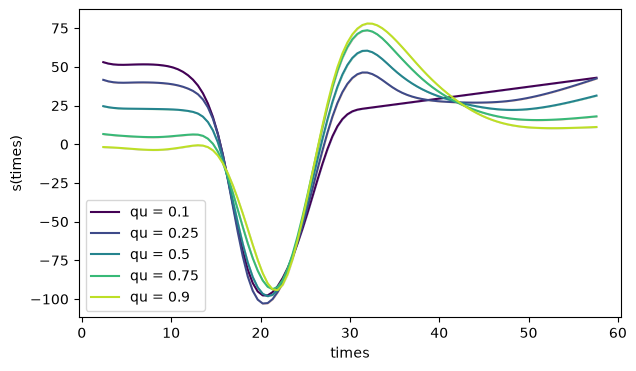

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
colors = plt.cm.viridis(np.linspace(0, 0.9, len(QUS)))
for fit, qu, color in zip(fits_mq, QUS, colors):
    gplt.continuous_1d(term=0, gam=fit, ax=ax, n_standard_errors=0,
                       plot_kwargs={"color": color, "label": f"qu = {qu}"})
ax.set(xlabel="times", ylabel="s(times)")
ax.legend();

And the fitted quantiles on top of the data:

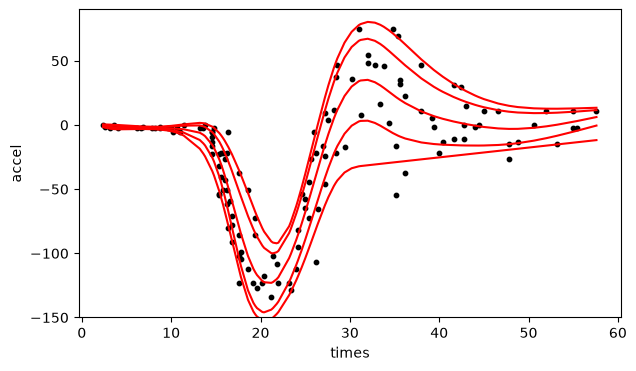

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(mcycle["times"], mcycle["accel"], s=10, color="black")
for fit, qu in zip(fits_mq, QUS):
    ax.plot(mcycle["times"], fit.predict()["accel"], color="red")
ax.set(xlabel="times", ylabel="accel", ylim=(-150, 90));

# Part 2: Modelling rainfall in Paraná

The `parana` dataset (R package `testGam`) has rainfall measured at 609 weather stations
in the state of Paraná, Brazil, over 53 weeks:

- **`ID`**: station identifier.
- **`LO`**, **`LA`**: longitude and latitude of the station, in degrees.
- **`EL`**: elevation of the station (metres, from the range 0–1446).
- **`seaDist`**: distance from the coast (probably km, from the range 1.6–616).
- **`TIME`**: week of the year, 1–53. Week 53 is next to week 1, so it is modelled with
  a cyclic smooth (`bs = "cc"`).
- **`PREC`**: rainfall. From the values (e.g. 0.357 = 2.5 / 7) it looks like the
  average daily rainfall over the week, probably in mm.

Rainfall is very skewed: most weeks are dry and a few have a lot of rain. Quantile GAMs
can model, e.g., the heavy-rain weeks (the 80% or 90% quantile) without choosing a
distribution for the rainfall.

,ID,LA,LO,EL,TIME,PREC,seaDist
0,1.0,-22.8511,-50.8744,365.0,1,0.357143,391.259436
1,1.0,-22.8511,-50.8744,365.0,2,2.742857,391.259436
2,1.0,-22.8511,-50.8744,365.0,3,17.128571,391.259436
3,1.0,-22.8511,-50.8744,365.0,4,4.328571,391.259436
4,1.0,-22.8511,-50.8744,365.0,5,7.042857,391.259436


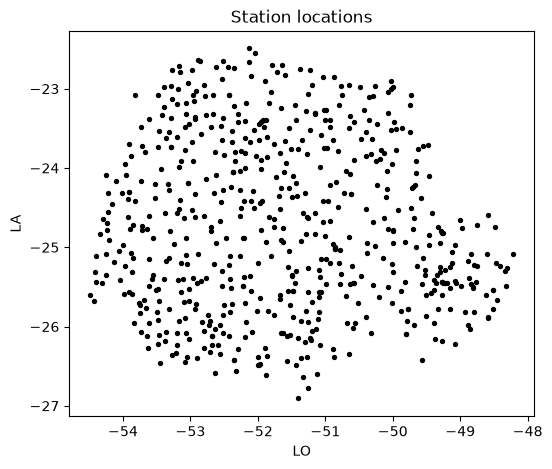

In [13]:
parana = load_rdata_dataframe_from_url(
    "https://raw.githubusercontent.com/mfasiolo/testGam/master/data/parana.rda"
).reset_index(drop=True)
display(parana.head())

stations = parana[parana["TIME"] == 1]
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(stations["LO"], stations["LA"], s=8, color="black")
ax.set(xlabel="LO", ylabel="LA", title="Station locations");

## Model for the 80% quantile

R:

```r
fit <- qgamV(PREC ~ s(LO, LA, k = 25) + s(seaDist) + s(TIME, bs = "cc") + s(EL),
             aQgam = list(discrete = TRUE), 
             data = parana, 
             qu = 0.8)
```

`qgamV` is `qgam` + `getViz` from mgcViz. `discrete = TRUE` uses mgcv's faster fitting
method for large datasets (`bam` with discretised covariates).

Estimating learning rate. Each dot corresponds to a loss evaluation. 
qu = 0.8..........done 


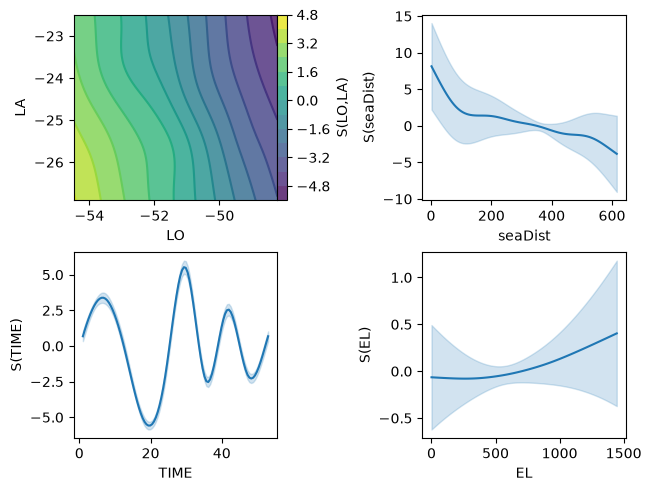

In [14]:
fit = fit_qgam(
    {
        "PREC": [
            S("LO", "LA", k=25),
            S("seaDist"),
            S("TIME", bs=CubicSpline(cyclic=True)),
            S("EL"),
        ]
    },
    data=parana,
    qu=0.8,
    discrete=True,
)
gplt.plot(fit, ncols=2);

## Checking the model

### QQ-plot

`qq(fit, CI = "normal")` is from mgcViz, so it is called through rpy2:

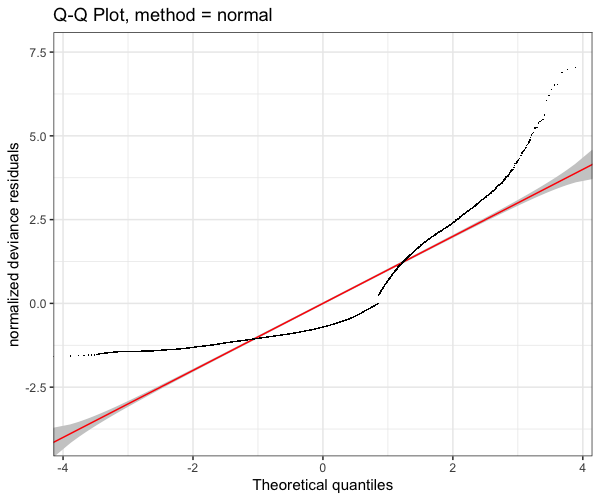

In [15]:
ro.globalenv["fit_r"] = fit.fit_state.rgam
show_r_plot('print(qq(getViz(fit_r), CI = "normal"))', width=6, height=5)

### Proportion of negative residuals

For the 80% quantile, about 80% of the observations should be below the fitted values:

In [16]:
res = parana["PREC"].to_numpy() - np.array(fit.fit_state.rgam.rx2("fitted.values"))
print(f"Proportion of negative residuals: {np.mean(res < 0):.4f}")

Proportion of negative residuals: 0.8027


The overall proportion is right, but it can still be wrong in some places. We check it
along elevation, `check1D(fit, x = "EL") + l_gridQCheck1D()` in R:

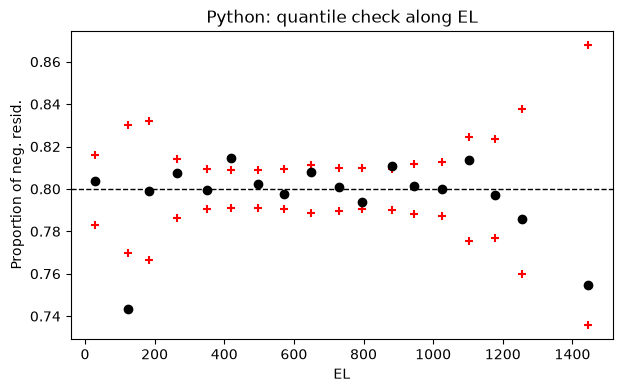

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
quantile_check_1d(parana["EL"], res, qu=0.8, ax=ax, xlabel="EL")
ax.set_title("Python: quantile check along EL");

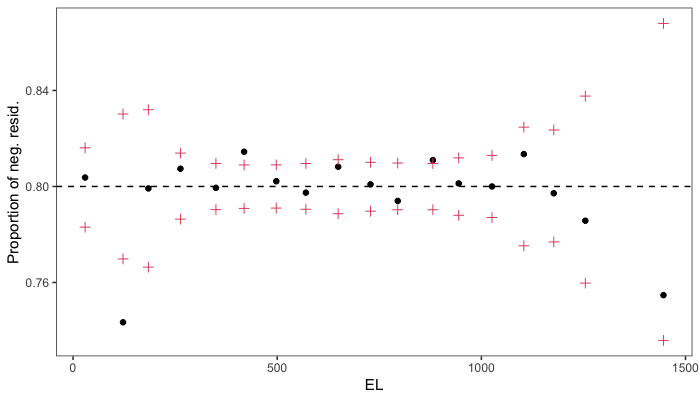

In [18]:
show_r_plot('print(check1D(getViz(fit_r), x = "EL") + l_gridQCheck1D())', width=7, height=4)

And in space, `check2D(fit, x1 = "LO", x2 = "LA") + l_gridQCheck2D()` in R:

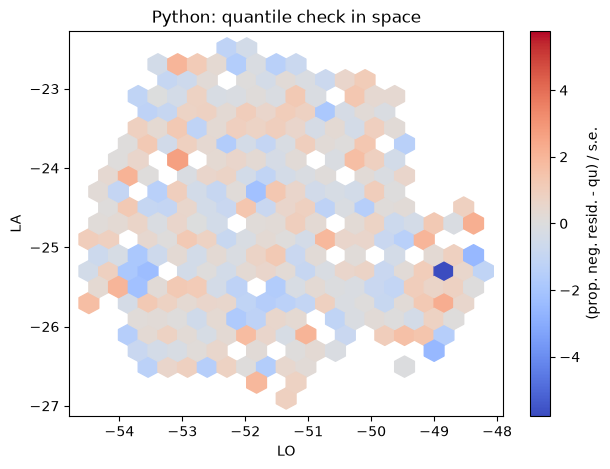

In [19]:
fig, ax = plt.subplots(figsize=(7, 5))
quantile_check_2d(parana["LO"], parana["LA"], res, qu=0.8, ax=ax, xlabel="LO",
                  ylabel="LA")
ax.set_title("Python: quantile check in space");

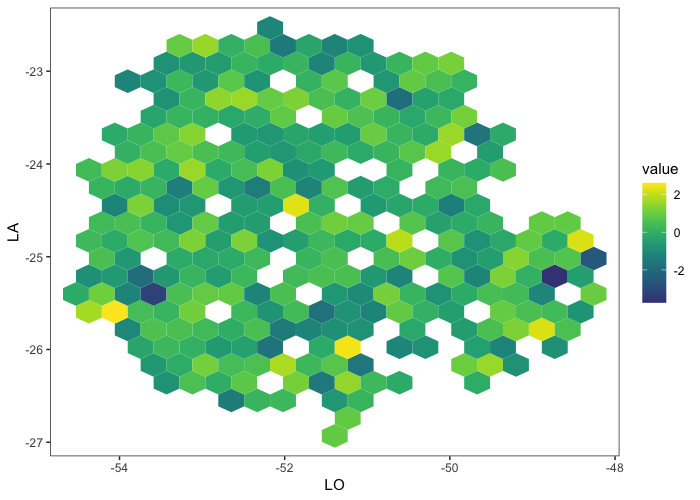

In [20]:
show_r_plot('print(check2D(getViz(fit_r), x1 = "LO", x2 = "LA") + l_gridQCheck2D())',
            width=7, height=5)

> The two plots don't have the same hexagons: mgcViz uses smaller hexagons and places
> them differently (see Demo 2). Bigger hexagons contain more observations, so the same
> deviation from `qu` gives a larger standardised value, which is why the Python colour
> scale goes further. Both plots show the same areas, e.g. the dark blue hexagon near
> LO = -49, LA = -25.3 where the fitted 80% quantile is too high.

## Several quantiles

R:

```r
fitM <- mqgamV(PREC ~ s(LO, LA, k = 25) + s(seaDist) + s(TIME, bs = "cc") + s(EL),
               aQgam = list(discrete = TRUE), data = parana,
               qu = seq(0.1, 0.9, length.out = 5))
```

In [21]:
QUS_RAIN = np.linspace(0.1, 0.9, 5)
fits_rain = fit_mqgam(
    {
        "PREC": [
            S("LO", "LA", k=25),
            S("seaDist"),
            S("TIME", bs=CubicSpline(cyclic=True)),
            S("EL"),
        ]
    },
    data=parana,
    qus=QUS_RAIN,
    discrete=True,
)

Estimating learning rate. Each dot corresponds to a loss evaluation. 
qu = 0.5......done 
qu = 0.3....................done 
qu = 0.7.........done 
qu = 0.1.................done 
qu = 0.9........done 


`plot(fitM, select = 1)`: the spatial effect `s(LO, LA)` for each quantile. The dots are
the stations (passing `data=stations` shows each station once, not once per week).
Each panel has its own colour scale, because the effect is much larger for the high
quantiles.

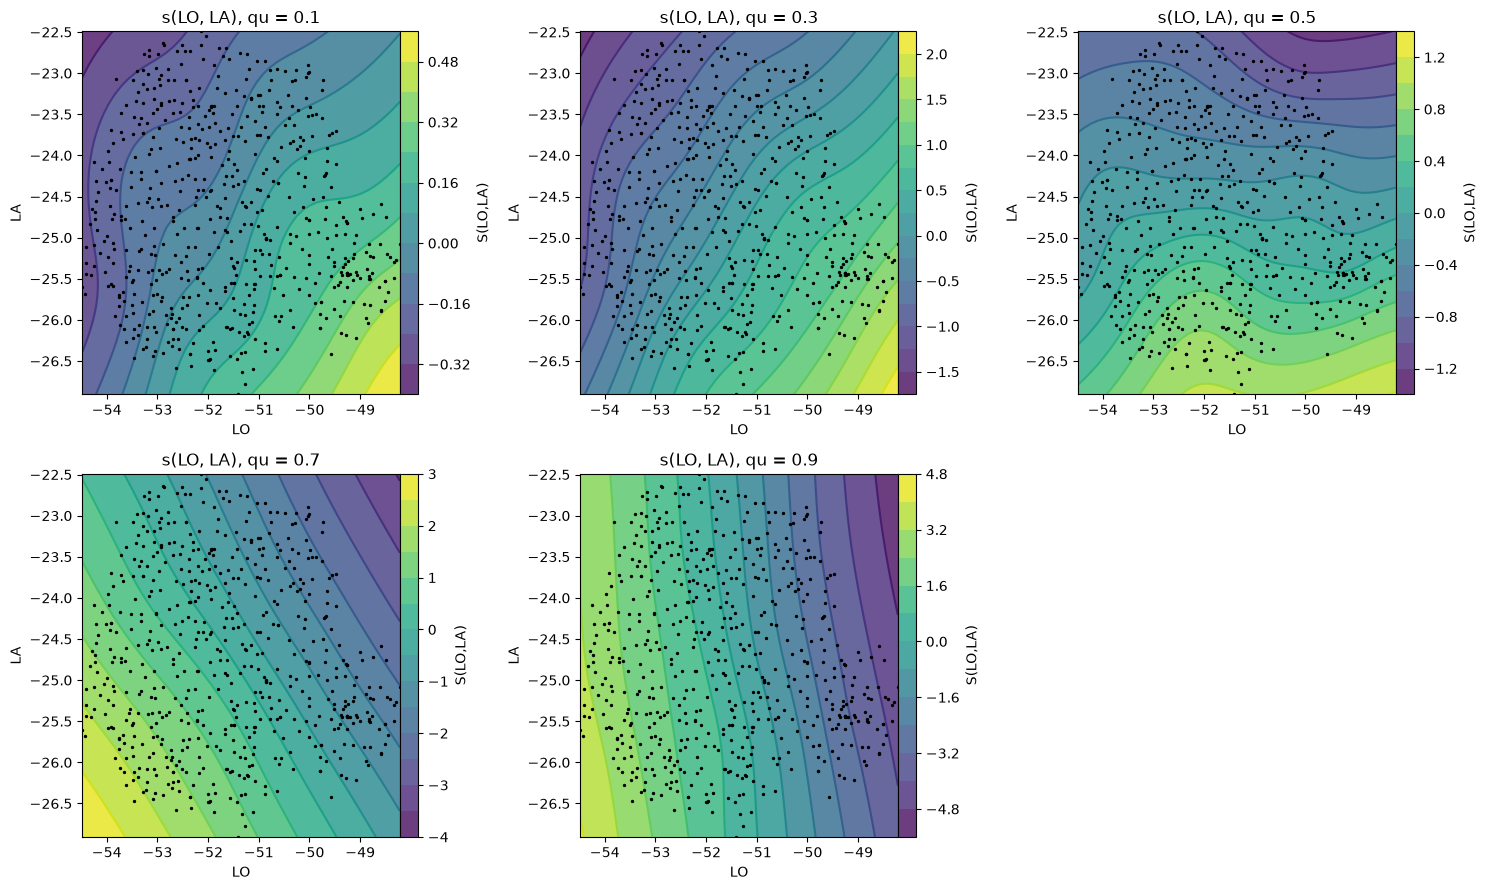

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for fit_q, qu, ax in zip(fits_rain, QUS_RAIN, axes.ravel()):
    gplt.continuous_2d(term=0, gam=fit_q, ax=ax, data=stations,
                       scatter_kwargs={"s": 2, "color": "black"})
    ax.set_title(f"s(LO, LA), qu = {qu:.1f}")
axes[-1, -1].remove()  # 5 quantiles, 6 panels
fig.tight_layout()

`plot(fitM, select = 2:4)`: the effects of `seaDist`, `TIME` and `EL` for each quantile.

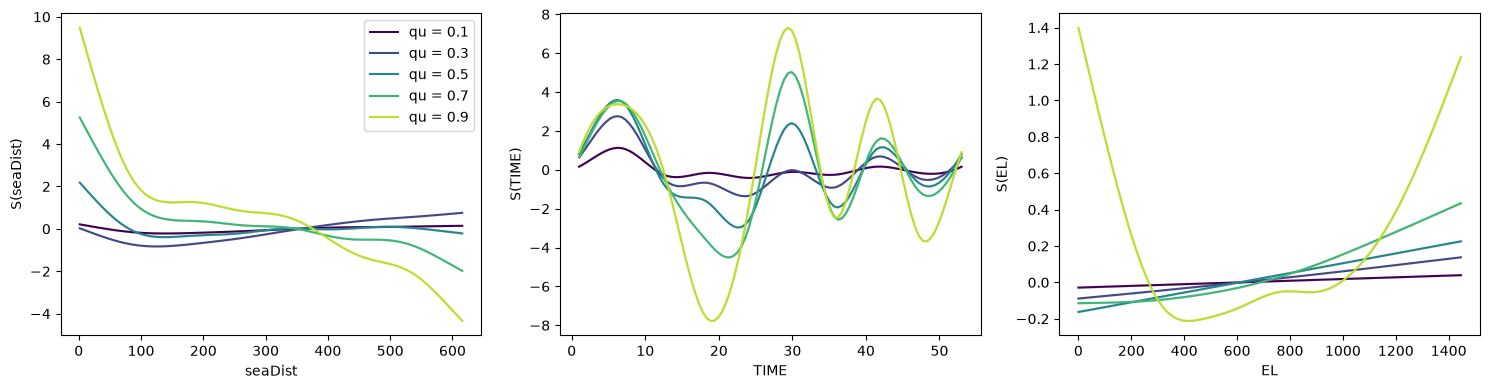

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = plt.cm.viridis(np.linspace(0, 0.9, len(QUS_RAIN)))
for term_idx, ax in zip([1, 2, 3], axes):
    for fit_q, qu, color in zip(fits_rain, QUS_RAIN, colors):
        gplt.continuous_1d(term=term_idx, gam=fit_q, ax=ax, n_standard_errors=0,
                           plot_kwargs={"color": color, "label": f"qu = {qu:.1f}"})
axes[0].legend()
fig.tight_layout()

### 3D view of the spatial effect for the 90% quantile

`plotRGL(sm(fitM[[5]], 1))` in R. As in Demo 2, plotly gives an interactive 3D plot
(drag to rotate, scroll to zoom), with the grey surfaces at ± 1 standard error. Grid
points far from any station are left out, because there the smooth is only extrapolating.

In [24]:
def lo_la_grid(n=60, too_far=0.3):
    """Grid over the stations, with a mask for points far (in degrees) from all stations."""
    lo_grid, la_grid = np.meshgrid(
        np.linspace(parana["LO"].min(), parana["LO"].max(), n),
        np.linspace(parana["LA"].min(), parana["LA"].max(), n),
    )
    dist, _ = cKDTree(stations[["LO", "LA"]].to_numpy()).query(
        np.column_stack([lo_grid.ravel(), la_grid.ravel()])
    )
    return lo_grid, la_grid, (dist > too_far).reshape(lo_grid.shape)


def plot_surface_3d(lo_grid, la_grid, effect, far, title, se_mult=1):
    surface = np.where(far, np.nan, effect.fit.reshape(lo_grid.shape))
    se = np.where(far, np.nan, effect.se.reshape(lo_grid.shape))
    band = {"colorscale": [[0, "grey"], [1, "grey"]], "showscale": False, "opacity": 0.3}
    fig = go.Figure([
        go.Surface(x=lo_grid, y=la_grid, z=surface, colorscale="Viridis",
                   colorbar={"title": "effect"}, name="effect"),
        go.Surface(x=lo_grid, y=la_grid, z=surface + se_mult * se, name="+ SE", **band),
        go.Surface(x=lo_grid, y=la_grid, z=surface - se_mult * se, name="- SE", **band),
    ])
    fig.update_layout(title=title, width=750, height=650,
                      scene={"xaxis_title": "LO", "yaxis_title": "LA",
                             "zaxis_title": "effect"})
    fig.show()


lo_grid, la_grid, far = lo_la_grid()
fit_09 = fits_rain[-1]
effect = fit_09.partial_effect(
    fit_09.predictors["PREC"][0],
    data={"LO": lo_grid.ravel(), "LA": la_grid.ravel()},
    compute_se=True,
)
plot_surface_3d(lo_grid, la_grid, effect, far, "s(LO, LA) for the 90% quantile")

**Static version.** The plotly figure above is interactive, but it needs JavaScript, so it
is not shown when the notebook is viewed on GitHub (or in other static viewers). The
same surface is drawn here with matplotlib as a static image, from two angles, so it
shows everywhere. The translucent grey surfaces are the ± 1 standard error surfaces.
`plot_surface_static` is defined in [`plot_helpers.py`](plot_helpers.py), next to the
notebooks, and is also used in Demo 2.

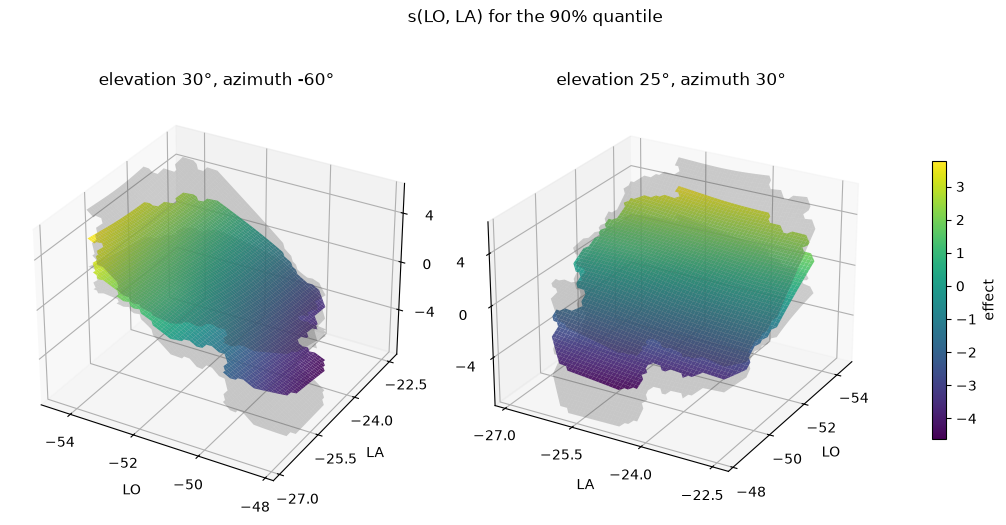

In [25]:
plot_surface_static(lo_grid, la_grid, effect.fit, effect.se, mask=far,
                    xlabel="LO", ylabel="LA", title="s(LO, LA) for the 90% quantile")


## Space-time effect

The spatial effect may change during the year. A tensor product smooth of space and time
lets it do that. R:

```r
fit4 <- qgamV(PREC ~ te(LO, LA, TIME, d = c(2, 1), k = c(20, 10), bs = c("tp", "cc")) +
                     s(EL),
              aQgam = list(discrete = TRUE), data = parana, qu = 0.9)
```

`d = c(2, 1)` means that `(LO, LA)` form one 2D thin plate spline margin and `TIME` a 1D
cyclic margin.

> **Note:** with `discrete = TRUE`, mgcv reorders the margins of a tensor product so that
> it is stored as `te(TIME,LO,LA)`. pymgcv finds a fitted term by its name, so we write the
> term in that order: `T("TIME", "LO", "LA", d=(1, 2), ...)`. This is the same model as in
> R, and gives the same numbers.

In [26]:
fit4 = fit_qgam(
    {
        "PREC": [
            T("TIME", "LO", "LA", d=(1, 2), k=(10, 20),
              bs=(CubicSpline(cyclic=True), ThinPlateSpline())),
            S("EL"),
        ]
    },
    data=parana,
    qu=0.9,
    discrete=True,
)
space_time = fit4.predictors["PREC"][0]

Estimating learning rate. Each dot corresponds to a loss evaluation. 
qu = 0.9........done 


`plotSlice(sm(fit4, 1), fix = list(TIME = round(seq(1, 53, length.out = 6))))` plots the
spatial effect at 6 fixed weeks. In Python we compute the effect on a grid for each week
with `partial_effect`, and use one colour scale for all the panels so they can be
compared.

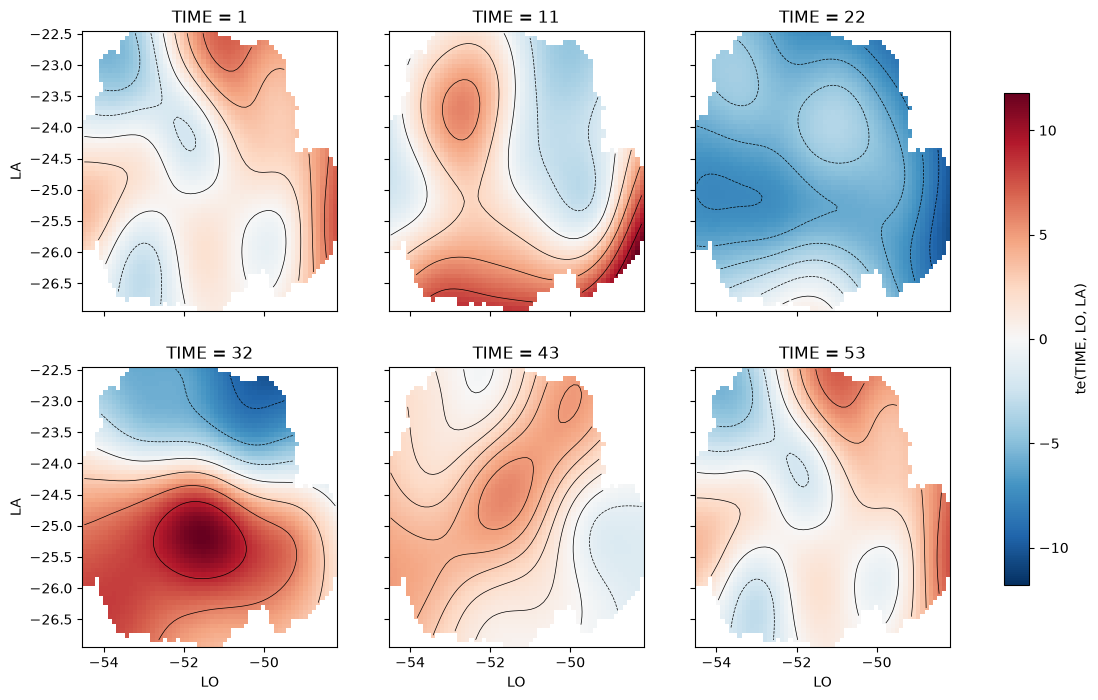

In [27]:
weeks = np.round(np.linspace(1, 53, 6)).astype(int)
slices = []
for week in weeks:
    eff = fit4.partial_effect(
        space_time,
        data={"LO": lo_grid.ravel(), "LA": la_grid.ravel(),
              "TIME": np.full(lo_grid.size, week)},
    )
    slices.append(np.where(far, np.nan, eff.reshape(lo_grid.shape)))

lim = np.nanmax(np.abs(slices))
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True)
for week, z, ax in zip(weeks, slices, axes.ravel()):
    mesh = ax.pcolormesh(lo_grid, la_grid, z, cmap="RdBu_r", vmin=-lim, vmax=lim,
                         shading="auto")
    ax.contour(lo_grid, la_grid, z, colors="black", linewidths=0.5)
    ax.set_title(f"TIME = {week}")
for ax in axes[-1]:
    ax.set_xlabel("LO")
for ax in axes[:, 0]:
    ax.set_ylabel("LA")
fig.colorbar(mesh, ax=axes, label="te(TIME, LO, LA)", shrink=0.8);

`plotRGL(sm(fit4, 1), fix = c(TIME = 11))`: the spatial effect in week 11 in 3D.

In [28]:
effect_w11 = fit4.partial_effect(
    space_time,
    data={"LO": lo_grid.ravel(), "LA": la_grid.ravel(),
          "TIME": np.full(lo_grid.size, 11)},
    compute_se=True,
)
plot_surface_3d(lo_grid, la_grid, effect_w11, far, "te(TIME, LO, LA) at TIME = 11")

Static version of the same plot (shown on GitHub):

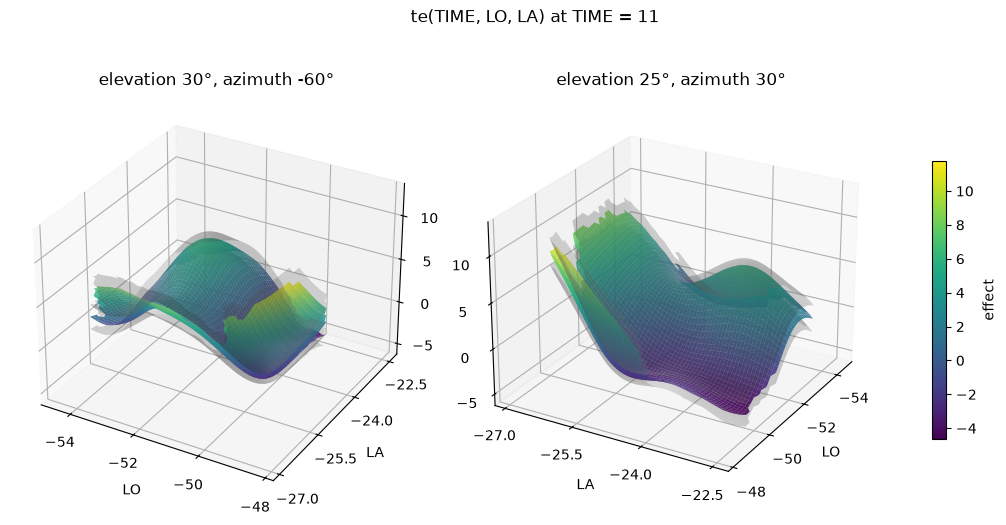

In [29]:
plot_surface_static(lo_grid, la_grid, effect_w11.fit, effect_w11.se, mask=far,
                    xlabel="LO", ylabel="LA", title="te(TIME, LO, LA) at TIME = 11")
